In [41]:
# Student Name: Aaron Baggot
# Student Number: C22716399
# TU856/4

In [1]:
from pathlib import Path
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt


In [2]:
# Save image
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Saving to:", OUT_DIR.resolve())

def show(title, img):
    plt.figure(figsize=(8,5))
    if img.ndim == 3:
        plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    else:
        plt.imshow(img, cmap="gray")
    plt.title(title);
    plt.axis("off");
    plt.show()

Saving to: /Users/aaronbaggot/Desktop/Image_Processing_Assignment_1/notebooks/outputs


In [3]:
# Load Image

# img_path = Path("/Users/aaronbaggot/Desktop/Image_Processing_Assignment_1/data/raw/Shark 1.PNG")  
img_path = Path("/Users/aaronbaggot/Desktop/Image_Processing_Assignment_1/data/raw/Shark 2.PNG")
# img_path = Path("/Users/aaronbaggot/Desktop/Image_Processing_Assignment_1/data/raw/snow_cat.jpg")

I = cv.imread(str(img_path), cv.IMREAD_COLOR)

if I is None:
    raise Exception(f"Image not found: {img_path}")
h, w, = I.shape[:2]

# Resize x 2
S = cv.resize(I, dsize=(2*w, 2*h), interpolation=cv.INTER_CUBIC)

# Crop top left Tested on different values
# C = I[0:min(150, h), 0:min(200, w)]

# C = I[0:min(180, h), 0:min(270, w)]

C = I[0:min(100, h), 0:min(150, w)]


In [4]:
# Rotate 45 degrees on the same canvas
cx, cy = w // 2, h // 2

M = cv.getRotationMatrix2D((cx, cy), 45, 1.0)

R = cv.warpAffine(I, M, (w, h), flags=cv.INTER_LINEAR, borderMode =cv.BORDER_REFLECT)

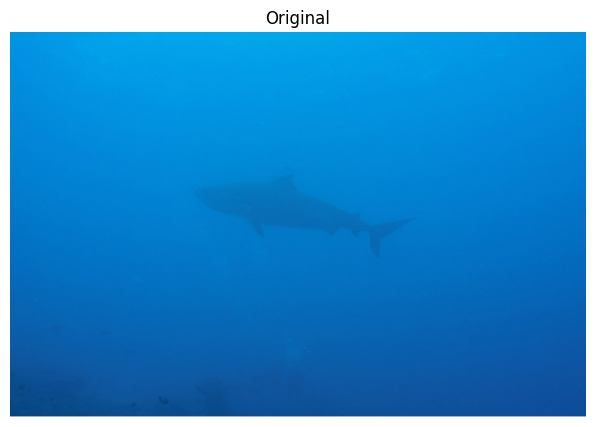

In [5]:
# Display the outputs
show("Original", I)

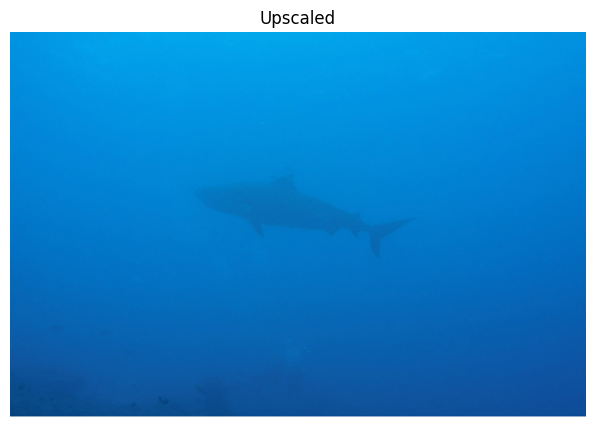

In [6]:
show("Upscaled", S)

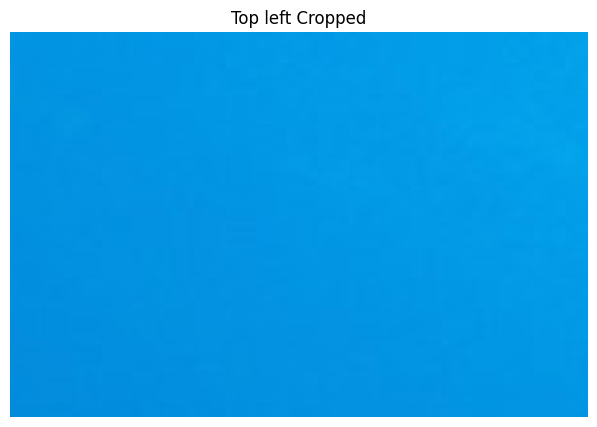

In [7]:
show("Top left Cropped", C)

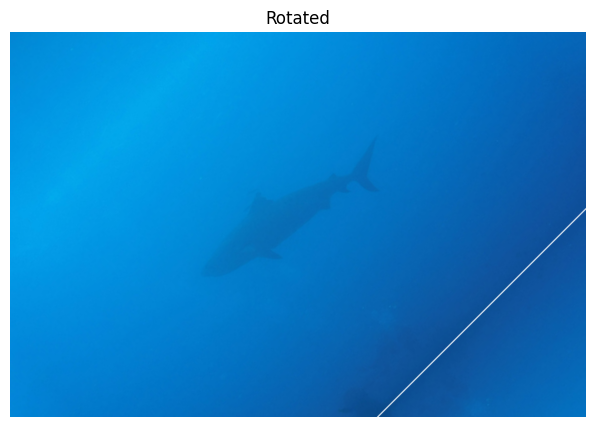

In [8]:
show("Rotated", R)

In [9]:
print("Saved outputs")

Saved outputs


In [10]:
# Save each image with discription
cv.imwrite(str(OUT_DIR / "01_Original.png"), I)
cv.imwrite(str(OUT_DIR / "02_Upscaled.png"), S)
cv.imwrite(str(OUT_DIR / "03_Cropped.png"), C)
cv.imwrite(str(OUT_DIR / "04_Rotated.png"), R)
print("Saved Outputs.")


Saved Outputs.


In [11]:
# The next section denoise the image using bilateral filter which smooths the flat water area 
# but keeps the edges of the shark sharp. 
# Converted the image to LAB colour and ran CLAHE on just the L channel.
# This lifts detail that is hidden by haze without blowing out highlights
# ClipLimit 3.0 and 8 x 8 tile size because 2.0 was too weak and 4.0 was to noisey, 3.0 was in the middle
# Finally I made a Gausian blur of the enhanced image and mix it back with addwrighted, 1.4 for the image and -0.4 for the blur
# This makes the underwater image clearer




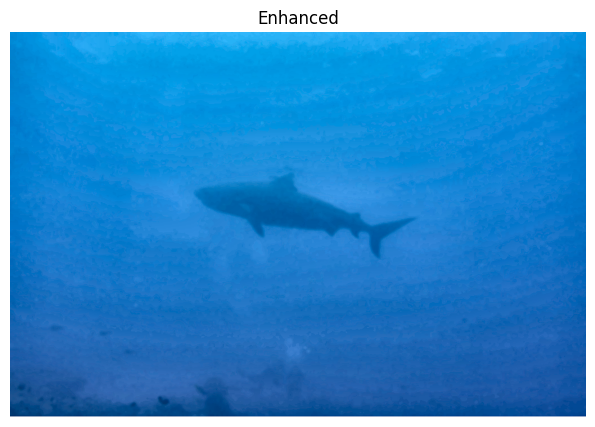

True

In [53]:
# Denoise whcih keeps edges contrast via CLAHE
den = cv.bilateralFilter(I, d=7, sigmaColor=75, sigmaSpace=75)

LAB = cv.cvtColor(den, cv.COLOR_BGR2LAB)
L, A, B = cv.split(LAB)

L2 = cv.createCLAHE(clipLimit=3.0, tileGridSize=(8,8)).apply(L)

# Testing different values
# L2 = cv.createCLAHE(clipLimit=2.0, tileGridSize=(8,8)).apply(L)
# L2 = cv.createCLAHE(clipLimit=4.0, tileGridSize=(8,8)).apply(L)


enh = cv.cvtColor(cv.merge([L2, A, B]), cv.COLOR_LAB2BGR)

blur = cv.GaussianBlur(enh, (0,0), 1.0)
enh = cv.addWeighted(enh, 1.4, blur, -0.4, 0)

show("Enhanced", enh)
cv.imwrite(str(OUT_DIR / "05_enhanced.png"), enh)




In [54]:
# This section is foreground mask, whereby convert the enhanced image to HSV and LAB. 
# From HSV I take S saturation and from LAB b blue,yellow. 
# Use Otsu's automatic threshold on each channel to get two rough masks
# Combine them with AND so pixel must look like shark in both views, removing the background
# If that AND is too strict (mask tiny) I auto-fallback to OR (or just b)
# if it’s too loose the mask huge I invert S to tighten
# Morphology cleans the mask. Close fill small holes, Open removes specks
# 7 x 7 ellipse used because 5 was weak and 9 trimmed finer details
# Only keep the largest connected component which is the shark
# This isolates the shark for the next steps

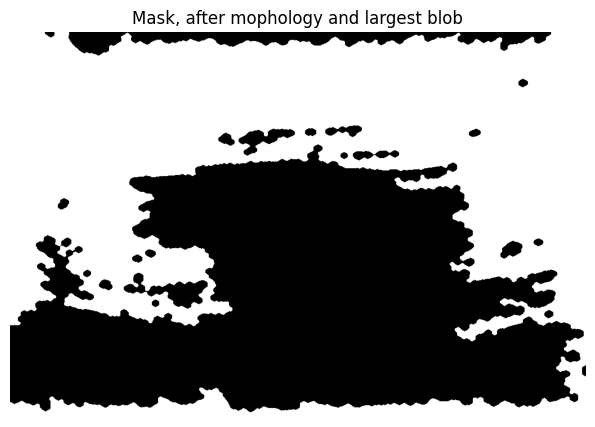

True

In [55]:
USE_AUTO_MASK_FALLBACK = globals().get("USE_AUTO_MASK_FALLBACK", True)
MORPH_KERNEL           = globals().get("MORPH_KERNEL", 7)

# Segment, Otsu on S & LAB-b, morphology, largest component
hsv = cv.cvtColor(enh, cv.COLOR_BGR2HSV); H,S,V = cv.split(hsv)
lab = cv.cvtColor(enh, cv.COLOR_BGR2LAB); L, a, b = cv.split(lab)

_, th_s = cv.threshold(S, 0, 255, cv.THRESH_BINARY+cv.THRESH_OTSU)
_, th_b = cv.threshold(b, 0, 255, cv.THRESH_BINARY+cv.THRESH_OTSU)

mask = cv.bitwise_and(th_s, th_b)

if USE_AUTO_MASK_FALLBACK:
    area_ratio = (mask.sum()/255) / (mask.shape[0]*mask.shape[1])
    if area_ratio < 0.01:  # too small → loosen
        mask_or = cv.bitwise_or(th_s, th_b)
        area_or = (mask_or.sum() / 255) / (mask.shape[0]*mask.shape[1])
        mask = mask_or if area_or > area_ratio else th_b
    elif area_ratio > 0.95:  # too big → tighten
        _, s_inv = cv.threshold(255 - S, 0, 255, cv.THRESH_BINARY+cv.THRESH_OTSU)
        mask = cv.bitwise_and(s_inv, th_b)


# Morphology and largest blob 
k = cv.getStructuringElement(cv.MORPH_ELLIPSE, (7,7))

# k = cv.getStructuringElement(cv.MORPH_ELLIPSE, (5,5))
# k = cv.getStructuringElement(cv.MORPH_ELLIPSE, (9,9))


mask = cv.morphologyEx(mask, cv.MORPH_CLOSE, k, iterations=2)
mask = cv.morphologyEx(mask, cv.MORPH_OPEN,  k, iterations=1)

num, labels = cv.connectedComponents(mask)
if num > 1:
    sizes = [(labels==i).sum() for i in range(1, num)]
    mask = np.where(labels==(1+int(np.argmax(sizes))), 255, 0).astype(np.uint8)

show("Mask, after mophology and largest blob", mask)
cv.imwrite(str(OUT_DIR / "06_mask.png"), mask)

In [56]:
# On some images (e.g., Shark 2) the plain S AND b mask can be empty; 
# if that happens, I automatically relax it (use OR, or just b). 
# If the mask is too big, I invert S to prefer higher-saturation pixels. 
# This keeps the code short, avoids manual toggles, and works reliably across both sharks.

In [57]:
# This section I straightened the shark and tidyed the frame with a clean background
# Find the largest shape and get its angle using minAreaRect. Rotated by that angle so the shark is nearly horizontal 
# Cropped around the rotated mask and for the background I replace the shark pixels 
# and replace the rest with a solid colour, this was choosen by sampling a 10 pixel border around the image and taking the median
# The final image shows the shark centered

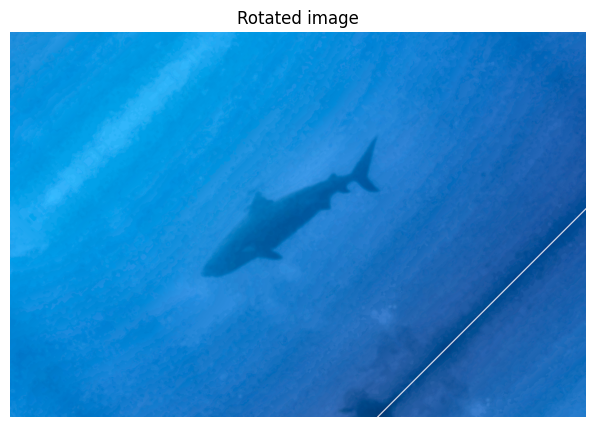

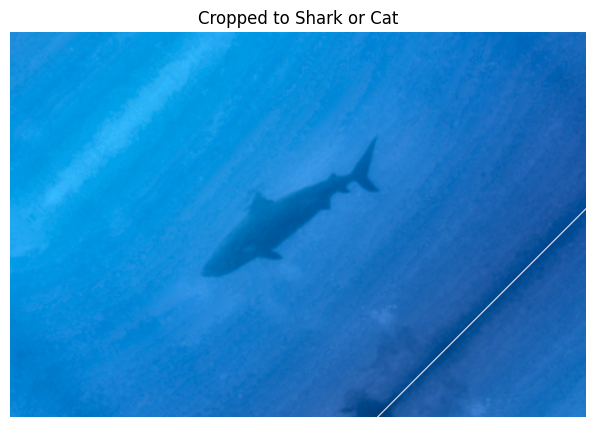

All saved in: outputs


In [58]:
# Rotate horizontal and crop tight
cnts,_ = cv.findContours(mask, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
if cnts:
    cnt = max(cnts, key=cv.contourArea)
    rect = cv.minAreaRect(cnt)
    angle = rect[-1]
    if angle < -45:
        angle += 90
        
    Mrot = cv.getRotationMatrix2D((w//2, h//2),angle, 1.0)
    I_rot = cv.warpAffine(enh, M, (w, h), flags=cv.INTER_LINEAR, borderMode = cv.BORDER_REFLECT)
    m_rot = cv.warpAffine(mask, M, (w, h), flags=cv.INTER_NEAREST, borderMode = cv.BORDER_CONSTANT)
    
    pts = cv.findNonZero(m_rot)
    x,y,ww,hh = cv.boundingRect(pts) if pts is not None else (0,0,w,h)
    crop = I_rot[y:y+hh, x:x+ww]
    mcrp = m_rot[y:y+hh, x:x+ww]



    show("Rotated image", I_rot)
    show("Cropped to Shark or Cat", crop)
    cv.imwrite(str(OUT_DIR / "07_rotated.png"), I_rot)
    cv.imwrite(str(OUT_DIR / "08_cropped.png"), crop)

else:
    crop, mcrp = enh, mask

    
# Compose clean background with solid median for borders
inv = (mcrp == 0).astype(np.uint8) * 255
border = np.zeros_like(inv)
border[10,:]=255; 
border[-10:,:]=255;
border[10,:]=255; 
border[:,-10:]=255


samples = cv.bitwise_and(crop, crop, mask=cv.bitwise_and(inv, border)).reshape(-1, 3)
samples = samples[(samples.sum(1) > 0)]
color = tuple(map(int, (np.median(samples,0) if len(samples) else np.array([210,220,230]))))
                        
canvas = np.full_like(crop, color, dtype = np.uint8)
final = cv.add(cv.bitwise_and(crop, crop, mask = mcrp),
               cv.bitwise_and(canvas, canvas, mask = cv.bitwise_not(mcrp)))

plt.show("Final Clean background", final)
cv.imwrite(str(OUT_DIR /"07_final.png"), final)
print("All saved in:", OUT_DIR)







In [59]:
# The steps worked the way I wanted. The denoise and CLAHE made the image clearer
# the simple mask s and b with the small fallback picked out the shark or cat without me having to tweak settings everytime
# The morphology removed small bits and keeping the biggest shapeleaving with just the shark or cat.
# Rotate and crop made the images look neat
# the solid background made it clean and simple
# Having tested in 3 different images it still had a resonable outcome
# Overall, I am happy that it is easy to run  

In [60]:

# [1] “OpenCV + Python Binarization (Thresholding),” codingwalks. Accessed: Oct. 11, 2025. 
#    [Online]. Available: https://en.codingwalks.com/entry/OpenCV-Python-Binarization-Thresholding
# [2] Kang & Atul, “angle of rotation by cv2.minAreaRect(),” TheAILearner. Accessed: Oct. 12, 2025. 
#    [Online]. Available: https://theailearner.com/tag/angle-of-rotation-by-cv2-minarearect/
# [3] “OpenCV: Histograms - 2: Histogram Equalization.” Accessed: Oct. 14, 2025. 
#    [Online]. Available: https://docs.opencv.org/4.x/d5/daf/tutorial_py_histogram_equalization.html

# [4] Jamileh Yousefi, “Image Binarization using Otsu Thresholding Algorithm,” 2015, Unpublished. doi: 10.13140/RG.2.1.4758.9284.

# [5] M. Huang, W. Yu, and D. Zhu, “An Improved Image Segmentation Algorithm Based on the Otsu Method,” in 2012 13th ACIS International Conference on Software Engineering, 
#     Artificial Intelligence, Networking and Parallel/Distributed Computing, Aug. 2012, pp. 135–139. doi: 10.1109/SNPD.2012.26.






